<a href="https://colab.research.google.com/github/eaedk/Machine-Learning-Tutorials-Updated/blob/main/04_nlp/04_embeddings_semantic_search.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧭 Application · Embeddings: searching by meaning, across languages

Type *"football results"* in English and find the right **Swahili** articles. Ask in French *"prix du carburant"*
(fuel price) and get Swahili news about prices and oil. No translation, no keyword in common. This is what **embeddings** do: they
turn a text into a list of numbers (a **vector**) such that texts with similar **meaning** get similar vectors.

**A little history.**
- **1957** · linguist J. R. Firth: *"You shall know a word by the company it keeps."* Words used in similar contexts
  have similar meanings: the *distributional hypothesis*.
- **1990** · *Latent Semantic Analysis*: compress a word-document matrix with linear algebra (SVD) to get word vectors.
- **2013** · *word2vec* (Google): vectors so good that `king − man + woman ≈ queen`.
- **2019** · *Sentence-BERT*: vectors for whole sentences, trained so that paraphrases end up close.
- **Today** · multilingual embedding models power search engines, recommendation, duplicate detection, and
  **RAG** (*Retrieval-Augmented Generation*): finding the right documents to give to a chatbot.

| Part | You will |
|---|---|
| 1 | build **word vectors from scratch** (Firth's idea, in 15 lines) |
| 2 | encode sentences with a pre-trained **multilingual** model and measure similarity |
| 3 | build a **semantic search engine** and compare it with keyword search |
| 4 | **see** the meaning space: clusters appear without labels |
| 5 | classify with **zero labels** (zero-shot) and **few labels** (few-shot) |
| 6 | understand how this becomes **RAG** |

⏱️ ~3 minutes.

In [1]:
# ⚙️ Setup: run me first! Finds the course toolkit `mlquest` (Windows, macOS, Linux and Colab).
import os, sys, subprocess, pathlib
if "google.colab" in sys.modules:  # on Colab: grab the repo (once) and the few missing packages
    if not pathlib.Path("/content/Machine-Learning-Tutorials-Updated").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/eaedk/Machine-Learning-Tutorials-Updated", "/content/Machine-Learning-Tutorials-Updated"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sentence-transformers"], check=True)
    os.chdir("/content/Machine-Learning-Tutorials-Updated")
ROOT = pathlib.Path.cwd()
while not (ROOT / "mlquest").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from mlquest import *  # paths, seed_everything, get_device, quest/checkpoint, Leaderboard...
set_style()
SEED = seed_everything(42)

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

quest("Searching by meaning", chapter="Track 4 · NLP · Embeddings", xp=200)
DEVICE = get_device()

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🗺️  QUEST · Searching by meaning
   Track 4 · NLP · Embeddings
   Reward: up to 200 XP
   You are: 🥚 Curious Rookie   ░░░░░░░░░░░░░░░░░░░░░░░░ 0/100 XP
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


⚙️  Using device: mps  (Apple Silicon GPU (Metal))


Our corpus: the Swahili news articles of the previous notebook (6 categories), we take 3 000 of them.

In [3]:
LABELS = ["uchumi", "kitaifa", "michezo", "kimataifa", "burudani", "afya"]
LABELS_EN = ["economy", "national", "sports", "international", "entertainment", "health"]
news = hf_parquet("community-datasets/swahili_news", "train", config="swahili_news")
news = news.sample(frac=1, random_state=SEED).groupby("label").head(500).reset_index(drop=True)   # ≤500 per category
news["category"] = news["label"].map(dict(enumerate(LABELS_EN)))
news["snippet"] = news["text"].str.split().str[:60].str.join(" ")     # first 60 words of each article
print(news.shape)
news["category"].value_counts()

(3000, 4)


category
entertainment    500
sports           500
national         500
international    500
economy          500
health           500
Name: count, dtype: int64

## 1. Word vectors from scratch: "the company it keeps" 🤝

Firth's idea, implemented with plain counting and linear algebra (the 1990s way):
1. Count how often each word appears **near** each other word (window of ±4 words): a big co-occurrence matrix.
2. Re-weight it with **PPMI** (*positive pointwise mutual information*): "do these words co-occur more than chance?"
3. Compress each row to 100 numbers with **SVD**. Each word is now a 100-dimensional vector.

In [4]:
from collections import Counter
from scipy.sparse import coo_matrix
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

docs = [re.findall(r"[a-z]+", t.lower()) for t in news["text"]]
vocab = [w for w, c in Counter(w for d in docs for w in d).most_common(8000)]
idx = {w: i for i, w in enumerate(vocab)}

rows, cols = [], []
for d in docs:
    ids = [idx[w] for w in d if w in idx]
    for i, wi in enumerate(ids):
        for wj in ids[max(0, i - 4):i] + ids[i + 1:i + 5]:
            rows.append(wi); cols.append(wj)
C = coo_matrix((np.ones(len(rows)), (rows, cols)), shape=(len(vocab), len(vocab))).tocsr()

total = C.sum(); pw = np.asarray(C.sum(1)).ravel() / total
C = C.tocoo()
pmi = np.log((C.data / total) / (pw[C.row] * pw[C.col]))
ppmi = coo_matrix((np.maximum(pmi, 0), (C.row, C.col)), shape=C.shape).tocsr()
word_vectors = normalize(TruncatedSVD(100, random_state=SEED).fit_transform(ppmi))

def neighbours(word, k=8):
    sims = word_vectors @ word_vectors[idx[word]]
    return [vocab[i] for i in np.argsort(-sims)[1:k + 1]]

for w in ["simba", "rais", "malaria", "bei", "mwanamuziki"]:   # simba (club), president, malaria, price, musician
    if w in idx:
        print(f"{w:>12} → {', '.join(neighbours(w))}")

       simba → yanga, azam, timu, bao, sc, mabao, mchezo, wekundu
        rais → magufuli, trump, kiongozi, makamu, madarakani, museveni, mteule, alimpongeza
     malaria → surua, dengue, ini, magonjwa, maradhi, ukimwi, usugu, kisukari
         bei → kuuza, tani, uzalishaji, korosho, mahindi, walanguzi, mbaazi, mazao
 mwanamuziki → mkongwe, maarufu, pop, jaydee, joachim, muziki, mwimbaji, hip


Nobody told the algorithm what a football club or a disease is. It discovered that *simba* keeps company with other
clubs and players, *malaria* with health words, *bei* (price) with economic words. Meaning emerged **from co-occurrence
alone**. word2vec (2013) learns similar vectors with a small neural network, at web scale.

In [5]:
checkpoint("embeddings/word_vectors", xp=40)

✅ Checkpoint · embeddings/word_vectors (+40 XP)
   █████████░░░░░░░░░░░░░░░ 40/100 XP


## 2. Sentence embeddings with a pre-trained multilingual model 🌍

Now we use **multilingual-E5-small** (Microsoft): a 118M-parameter transformer trained on billions of
sentence pairs in ~100 languages, Swahili included. It maps a whole sentence to a 384-number vector.

E5 models expect a prefix: `"query: "` for questions, `"passage: "` for documents.

**Cosine similarity** measures the angle between two vectors: 1 = same direction (same meaning), ~0 = unrelated.

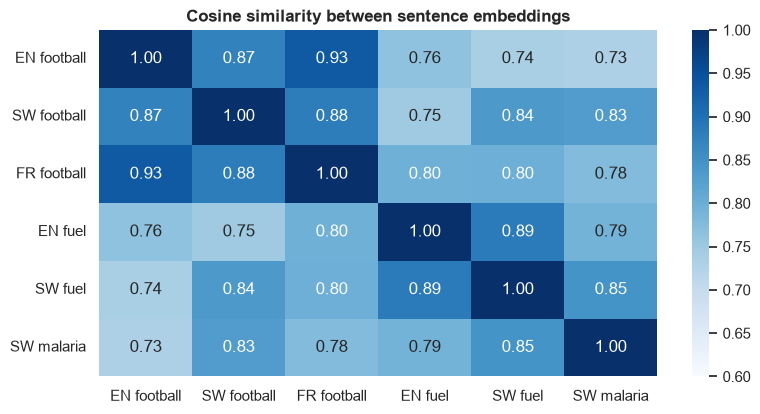

In [6]:
import logging, os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"        # quieter downloads
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
import transformers, huggingface_hub
transformers.logging.set_verbosity_error(); transformers.utils.logging.disable_progress_bar()
huggingface_hub.utils.logging.set_verbosity_error()
from sentence_transformers import SentenceTransformer

encoder = SentenceTransformer("intfloat/multilingual-e5-small", device=DEVICE)

sentences = [
    "The football team won the match 3-0.",            # English
    "Timu ya mpira wa miguu imeshinda mechi 3-0.",      # Swahili, same meaning
    "L'équipe de football a gagné le match 3 à 0.",     # French, same meaning
    "The price of fuel has increased again.",           # English, other topic
    "Bei ya mafuta imepanda tena.",                     # Swahili, fuel price
    "Wagonjwa wa malaria wameongezeka hospitalini.",    # Swahili, malaria patients increased
]
emb = encoder.encode(["query: " + s for s in sentences], normalize_embeddings=True)
sim = emb @ emb.T
short = ["EN football", "SW football", "FR football", "EN fuel", "SW fuel", "SW malaria"]
sns.heatmap(pd.DataFrame(sim, index=short, columns=short), annot=True, fmt=".2f", cmap="Blues", vmin=0.6, vmax=1)
plt.title("Cosine similarity between sentence embeddings"); plt.show()

The English and French football sentences are each closest to the other football sentences, and the English fuel
sentence to its Swahili translation: the model has learnt a shared "meaning space" for ~100 languages.

Two honest remarks:
- E5 similarities live in a narrow range (≈ 0.7-1.0). What matters is the **ranking**, not the absolute value.
- There is a small **language bias**: the three Swahili sentences are a bit closer to each other than they should be.
  Multilingual models are good, not perfect.

## 3. A semantic search engine in 10 lines 🔎

Index = embeddings of all articles. Search = embed the query, return the articles with the highest cosine similarity.
We compare it with a classic **keyword** search engine (TF-IDF).

In [7]:
doc_emb = encoder.encode(["passage: " + s for s in news["snippet"]], batch_size=64,
                         normalize_embeddings=True, show_progress_bar=False)
print(doc_emb.shape)

def semantic_search(query, k=3):
    q = encoder.encode(["query: " + query], normalize_embeddings=True)[0]
    scores = doc_emb @ q
    top = np.argsort(-scores)[:k]
    return news.iloc[top].assign(score=scores[top])[["score", "category", "snippet"]]

from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(sublinear_tf=True).fit(news["snippet"])
doc_tfidf = tfidf.transform(news["snippet"])

def keyword_search(query, k=3):
    scores = (doc_tfidf @ tfidf.transform([query]).T).toarray().ravel()
    top = np.argsort(-scores)[:k]
    return news.iloc[top].assign(score=scores[top])[["score", "category", "snippet"]]

pd.set_option("display.max_colwidth", 110)
for q in ["football match results", "prix du carburant", "malaria vaccine in hospitals"]:
    print(f"\n🔎 {q!r}  (semantic)")
    display(semantic_search(q))

(3000, 384)



🔎 'football match results'  (semantic)


,score,category,snippet
378,0.790886,sports,"KUELEKEA mchezo wa Ligi Kuu England utakaochezwa Jumapili kati ya Liverpool na Manchester United, kuna hat..."
1127,0.787253,sports,Dk Msolla ametoa maoni hayo siku moja baada ya Stars kupoteza mechi ya kwanza ya Kombe la michuano ya Bara...
1461,0.787030,sports,MISRI na Nigeria zimefungua milango ya hatua ya 16 Bora ya Fainali za Kombe la Mataifa ya Afrika (AFCON) 2...



🔎 'prix du carburant'  (semantic)


,score,category,snippet
2206,0.822387,economy,"Makamu Mwenyekiti wa Bodi hiyo, George Wasira alisema msimu uliopita bei elekezi ilikuwa Sh 700 kwa kilo n..."
2611,0.819002,economy,Tayari muda wa mwisho kutekeleza agizo hilo umefikia Aprili 30 mwaka huu na kuanzia Mei Mosi vituo vyote n...
1099,0.818439,economy,SERIKALI itaokoa kiasi cha Sh bilioni 400 mpaka Sh bilioni 675 kwa mwaka za mahitaji ya mafuta ya kula nch...



🔎 'malaria vaccine in hospitals'  (semantic)


,score,category,snippet
1306,0.812629,health,AVELINE KITOMARY-DAR ES SALAAM WITO umetolewa kwa wauguzi nchini kujikinga na mlipiko wa homa kali ya mapa...
658,0.811582,health,"Editha Karlo, Kigoma Serikali kupitia Wizara ya Afya, Maendeleo ya Jamii, Jinsia, Wazee na Watoto imepiga ..."
2177,0.810738,health,VERONICA ROMWALD – DAR ES SALAAM RIPOTI ya utafiti wa viashiria vya malaria ya mwaka 2017/18 inaonesha kiw...


In [8]:
print("Keyword search for the English query 'football match results':")
display(keyword_search("football match results"))

Keyword search for the English query 'football match results':


,score,category,snippet
0,0.0,entertainment,"Na Rhobi Chacha UNALIKUMBUKA kundi la Gangwe Mobb, hapo lazima utamtaja Haruna Kaena ‘Insepkta Haroun’ na ..."
1994,0.0,entertainment,"NAIROBI, KENYA BAADA ya kutokea Tanzania alipokuwa na ziara ya kutembelea baadhi ya vyombo vya habari anay..."
1995,0.0,international,"Pyongyang, Korea Kaskazini KOREA Kaskazini imefanyia majaribio ya injini kubwa maalum yenye uwezo wa kurus..."


The keyword engine is lost: the English words don't appear in Swahili articles (scores = 0, random results).
The semantic engine retrieves relevant articles from English and French queries.

Look closely at the French query: the results talk about prices (*bei*) and **mafuta**, which in Swahili means both
*fuel* and *oil* (including cooking oil!). The engine found the concept "price of oil/fuel", not exactly "fuel
price". Semantic search is fuzzy by nature: great recall, imperfect precision.

### How good is it? A quick evaluation
We use each category name as a query and measure **precision@10**: the share of the 10 retrieved articles that
belong to the right category.

In [9]:
queries = {"economy": "economy, business, trade and finance news", "national": "national news about Tanzania and its government",
           "sports": "sports news, football matches and athletes", "international": "international world news, foreign countries",
           "entertainment": "entertainment news, music, movies and celebrities", "health": "health news, diseases, hospitals and medicine"}
p_at_10 = {cat: (semantic_search(q, k=10)["category"] == cat).mean() for cat, q in queries.items()}
pd.Series(p_at_10, name="precision@10").to_frame().T

,economy,national,sports,international,entertainment,health
precision@10,0.6,0.4,1.0,0.7,0.8,0.6


In [10]:
checkpoint("embeddings/search", xp=50)

✅ Checkpoint · embeddings/search (+50 XP)
   █████████████████████░░░ 90/100 XP


## 4. Seeing the meaning space 🗺️

384 dimensions are impossible to look at, so we project them to 2D with **t-SNE**, which keeps close points close.
Colours are the true categories, which the model **never saw**.

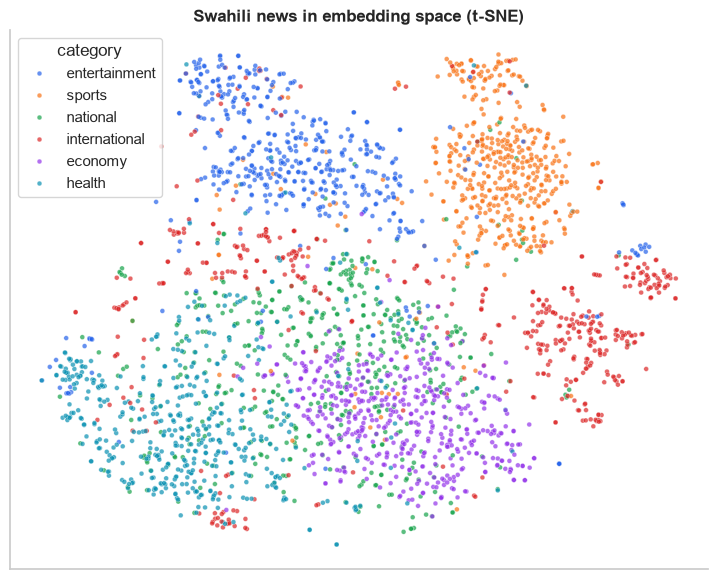

In [11]:
from sklearn.manifold import TSNE
xy = TSNE(n_components=2, perplexity=30, random_state=SEED, init="pca").fit_transform(doc_emb)
plt.figure(figsize=(9, 7))
sns.scatterplot(x=xy[:, 0], y=xy[:, 1], hue=news["category"], s=12, alpha=0.7, palette=PALETTE[:6])
plt.title("Swahili news in embedding space (t-SNE)"); plt.xticks([]); plt.yticks([]); plt.show()

Sports, entertainment and international news form clear islands, and health mostly groups together. *National*
news overlaps with *economy* and *health*: a story about a government hospital budget is all three at once. That's
the same confusion the supervised classifier had in the previous notebook. Embeddings reveal the structure
of a dataset before you train anything: a great EDA tool.

## 5. Classifying with zero labels, then a few 🎯

- **Zero-shot**: embed a short description of each class, and assign each article to the closest description.
  No training at all!
- **Few-shot**: take only **20 labelled articles per class**, train a logistic regression on the embeddings.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split

lb = Leaderboard("swahili_news_embeddings", metric="macro_F1")
label_emb = encoder.encode(["query: " + queries[c] for c in LABELS_EN], normalize_embeddings=True)
zero_shot = np.array(LABELS_EN)[(doc_emb @ label_emb.T).argmax(1)]
lb.add("Zero-shot (0 labels)", f1_score(news["category"], zero_shot, average="macro"))

train_idx, test_idx = train_test_split(np.arange(len(news)), test_size=0.5, stratify=news["category"], random_state=SEED)
for n_per_class in [5, 20, 100]:
    few = news.iloc[train_idx].groupby("category").sample(n=n_per_class, random_state=SEED).index
    clf = LogisticRegression(max_iter=2000, C=10).fit(doc_emb[few], news.loc[few, "category"])
    lb.add(f"Few-shot: {n_per_class} labels per class", f1_score(news.loc[test_idx, "category"], clf.predict(doc_emb[test_idx]), average="macro"))
lb.show()

📋 Zero-shot (0 labels): macro_F1 = 0.51888


📋 Few-shot: 5 labels per class: macro_F1 = 0.63954  👑 new best!
📋 Few-shot: 20 labels per class: macro_F1 = 0.75923  👑 new best!
📋 Few-shot: 100 labels per class: macro_F1 = 0.80676  👑 new best!


,,model,macro_F1
rank,,,
1,🥇,Few-shot: 100 labels per class,0.80676
2,🥈,Few-shot: 20 labels per class,0.75923
3,🥉,Few-shot: 5 labels per class,0.63954
4,,Zero-shot (0 labels),0.51888


With **zero** labelled examples we already get a useful classifier, and with a handful of labels per class, a
logistic regression on top of good embeddings gets surprisingly close to full fine-tuning. In a competition with
little data, *embeddings + simple model* is a fast, strong baseline.

## 6. From search to RAG 🤖

Large language models (LLMs) don't know your private documents and can invent facts. **RAG** fixes this:

```
question ──▶ embed ──▶ semantic search in YOUR documents ──▶ top-k passages
                                                                  │
               answer ◀── LLM ◀── "Answer using only these passages: …" + question
```

You just built the hardest part, the **retriever**. Swap the 3 000 news snippets for your company's documents,
plug any LLM, and you have a document chatbot. Most Zindi/Kaggle "LLM" challenges are won on the retrieval side.

## 🏆 Quest complete!

### 🚀 Your turn (bonus XP)
1. Search with your own queries, in your own language (Wolof, Hausa, Lingala…). Where does it break?
2. Compute `vector("mfalme") − vector("mwanamume") + vector("mwanamke")` with the from-scratch word vectors.
   Do you get something close to a queen (*malkia*)? (Hint: 3 000 articles is small; it may fail. Why?)
3. Detect **near-duplicate** articles: pairs with cosine similarity > 0.97.
4. Replace the model with `intfloat/multilingual-e5-base` and compare precision@10 and the few-shot scores.

In [13]:
checkpoint("embeddings/complete", xp=110)
badge("Meaning Navigator", "🧭")
progress()

✅ Checkpoint · embeddings/complete (+110 XP)
🎉 LEVEL UP! You are now 🐣 Data Explorer
   ████████████░░░░░░░░░░░░ 200/300 XP
╔══════════════════════════════════════╗
║ 🧭  BADGE UNLOCKED: Meaning Navigator ║
╚══════════════════════════════════════╝
🐣 Data Explorer
████████████░░░░░░░░░░░░ 200/300 XP
Checkpoints unlocked: 3
Badges: 🧭 Meaning Navigator
